# 04 - Precision Improvement: chẩn đoán + calibration + chọn ngưỡng

**Mục tiêu:** xác định vì sao Precision thấp và thực hiện giai đoạn cải thiện đầu tiên (calibration + ngưỡng theo ràng buộc `FPR <= 0.10`). Chưa làm two-stage, boosting, dữ liệu bổ sung hay kiểm tra nhãn bằng ground truth.

**Các tập dữ liệu:**

| Tập | Nguồn | Dùng cho |
|---|---|---|
| train-fit | 80% tập train đã làm sạch (giống notebook 03, `random_state=42`) | Fit model + calibration |
| validation | 20% còn lại của tập train | Chẩn đoán, chọn ngưỡng (phân bố train) |
| test-dev | 50% tập test chính thức (stratify theo `attack_cat`, `random_state=42`) | Chẩn đoán, kiểm chứng nhận định cũ, chọn ngưỡng (phân bố test) |
| **test-final** | 50% còn lại của tập test | **Chỉ đánh giá một lần ở cuối notebook** |

⚠️ **Minh bạch:** tập test chính thức (bao gồm cả nửa test-final) đã được xem ở các lần 1-2 (đánh giá, phân tích FP, bảng ngưỡng tham khảo, thực nghiệm phụ). Trong notebook này, test-final không được dùng cho bất kỳ chẩn đoán hay lựa chọn nào trước bước đánh giá cuối.

**Ký hiệu nguồn số liệu:** `[ĐO]` đo trực tiếp · `[TÍNH]` tính từ số đo · `[GIẢ THUYẾT]` chưa kiểm chứng

In [1]:
import os

# Tự nhận diện môi trường: Colab (mount Google Drive) hoặc máy local (Google Drive for Desktop)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/5G_IDS_Project'
except ImportError:
    # Notebook nằm trong 5G_IDS_Project/notebooks -> thư mục project là thư mục cha
    BASE = os.path.abspath('..')

print("Thư mục project:", BASE)

Thư mục project: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project


In [2]:
import json
import numpy as np
import pandas as pd

QUICK = os.environ.get('QUICK') == '1'
RS = 42
N_TREES = 30 if QUICK else 300
CAL_CV = 2 if QUICK else 5
FPR_MAX = 0.10

cleaned_dir = os.path.join(BASE, 'data', 'cleaned')
models_dir = os.path.join(BASE, 'models')
raw_dir = os.path.join(BASE, 'data', 'raw', 'CSV Files', 'Training and Testing Sets')
train = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_training-set.parquet'))
test = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_testing-set.parquet'))

target_cols = ['label', 'attack_cat']
categorical_cols = ['proto', 'service', 'state']
removed_cols = ['id', 'ct_state_ttl', 'sttl', 'dttl', 'ct_dst_ltm', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_srv_ltm',
                'ct_srv_src', 'ct_dst_sport_ltm', 'is_sm_ips_ports', 'ct_ftp_cmd', 'is_ftp_login']


def features(df):
    return df.drop(columns=target_cols).astype({c: str for c in categorical_cols})


X, y = features(train), train['label']
assert not set(target_cols + removed_cols) & set(X.columns)
print('QUICK mode' if QUICK else 'FULL mode')

FULL mode


In [3]:
from sklearn.model_selection import train_test_split

# Validation: tái sử dụng đúng cách chia của notebook 03
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)

# Chia tập test chính thức thành test-dev / test-final (stratify theo attack_cat)
dev_idx, final_idx = train_test_split(test.index, test_size=0.5, stratify=test['attack_cat'], random_state=RS)
test_dev, test_final = test.loc[dev_idx], test.loc[final_idx]
X_dev, y_dev = features(test_dev), test_dev['label']

split_file = os.path.join(cleaned_dir, 'test_split_v3.csv')
if not QUICK:
    pd.DataFrame({'test_index': test.index, 'split': np.where(test.index.isin(final_idx), 'test_final', 'test_dev')}
                 ).to_csv(split_file, index=False)

sizes = pd.DataFrame({
    'n': [len(X_tr), len(X_val), len(test_dev), len(test_final)],
    'attack_prevalence': [y_tr.mean(), y_val.mean(), y_dev.mean(), test_final['label'].mean()],
}, index=['train-fit', 'validation', 'test-dev', 'test-final'])
display(sizes.round(4))   # [ĐO] (prevalence test-final chỉ là tỷ lệ nhãn, không dùng model)

,n,attack_prevalence
train-fit,79147,0.4964
validation,19787,0.4964
test-dev,25283,0.3665
test-final,25284,0.3665


In [4]:
# [ĐO] Tỷ lệ Attack trước và sau làm sạch -> bước bỏ trùng có làm đổi tỷ lệ lớp không?
raw_tr = pd.read_csv(os.path.join(raw_dir, 'UNSW_NB15_training-set.csv'), usecols=['label'])
raw_te = pd.read_csv(os.path.join(raw_dir, 'UNSW_NB15_testing-set.csv'), usecols=['label'])
display(pd.DataFrame({'raw (CSV gốc)': [raw_tr['label'].mean(), raw_te['label'].mean()],
                      'cleaned (sau bỏ trùng)': [train['label'].mean(), test['label'].mean()]},
                     index=['train', 'test']).round(4))

,raw (CSV gốc),cleaned (sau bỏ trùng)
train,0.6806,0.4964
test,0.5506,0.3665


## 1. Baseline: tái tạo model hiện tại

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, brier_score_loss
import joblib

# Tham số tốt nhất của lần 2 (notebook 03, chọn bằng CV trên train-fit)
v2_metrics = json.load(open(os.path.join(models_dir, 'random_forest_v2_metrics.json'), encoding='utf-8'))
best_params = v2_metrics['best_params']
print('Tham số lần 2:', best_params)


def make_model(**rf_params):
    preprocess = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)],
                                   remainder='passthrough', verbose_feature_names_out=False)
    params = dict(n_estimators=N_TREES, random_state=RS, n_jobs=-1) | best_params | rf_params
    return Pipeline([('preprocess', preprocess), ('rf', RandomForestClassifier(**params))])


def metrics_at(y_true, proba, threshold):
    # Attack nếu P(Attack) >= threshold
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'threshold': threshold, 'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
            'accuracy': (tp + tn) / len(pred), 'precision': tp / max(tp + fp, 1), 'recall': tp / (tp + fn),
            'f1': 2 * tp / max(2 * tp + fp + fn, 1), 'fpr': fp / (fp + tn), 'prevalence': float(np.mean(y_true))}


def table(rows):
    df = pd.DataFrame(rows).T
    fmt = {c: '{:.4f}' for c in ['threshold', 'accuracy', 'precision', 'recall', 'f1', 'fpr', 'prevalence']}
    display(df.style.format(fmt))
    return df


# Model A: Random Forest (tham số lần 2) fit trên train-fit, chưa calibrate
model_A = make_model().fit(X_tr, y_tr)
proba_A = {'validation': model_A.predict_proba(X_val)[:, 1], 'test-dev': model_A.predict_proba(X_dev)[:, 1]}
ys = {'validation': y_val, 'test-dev': y_dev}

base_rows = {f'A @0.5 - {s}': metrics_at(ys[s], proba_A[s], 0.5) for s in ys}
# Kiểm chứng số liệu cũ: model lần 1 và lần 2 đã lưu, chỉ trên test-dev
run1 = joblib.load(os.path.join(models_dir, 'random_forest.joblib'))
run2 = joblib.load(os.path.join(models_dir, 'random_forest_v2.joblib'))
base_rows['Lần 1 (đã lưu) @0.5 - test-dev'] = metrics_at(y_dev, run1.predict_proba(X_dev)[:, 1], 0.5)
base_rows['Lần 2 (đã lưu) @0.515 - test-dev'] = metrics_at(y_dev, run2.estimator_.predict_proba(X_dev)[:, 1],
                                                          float(run2.best_threshold_))
baseline_table = table(base_rows)   # [ĐO]

Tham số lần 2: {'min_samples_leaf': 1, 'max_samples': 0.7, 'max_features': 0.5, 'max_depth': 20, 'class_weight': None}


,threshold,TP,TN,FP,FN,accuracy,precision,recall,f1,fpr,prevalence
A @0.5 - validation,0.5000,9407.000000,9039.000000,926.000000,415.000000,0.9322,0.9104,0.9577,0.9335,0.0929,0.4964
A @0.5 - test-dev,0.5000,8806.000000,11810.000000,4207.000000,460.000000,0.8154,0.6767,0.9504,0.7905,0.2627,0.3665
Lần 1 (đã lưu) @0.5 - test-dev,0.5000,8803.000000,11767.000000,4250.000000,463.000000,0.8136,0.6744,0.9500,0.7888,0.2653,0.3665
Lần 2 (đã lưu) @0.515 - test-dev,0.5152,8741.000000,12157.000000,3860.000000,525.000000,0.8266,0.6937,0.9433,0.7995,0.2410,0.3665


## 2. Chẩn đoán Precision

### 2.1 Quan hệ Precision - TPR - FPR - tỷ lệ Attack

`Precision = TPR·π / (TPR·π + FPR·(1-π))`. Dòng `[ĐO]` lấy trực tiếp từ ma trận nhầm lẫn; các dòng `[TÍNH]` thay một đại lượng để tách ảnh hưởng.

In [6]:
def precision_formula(tpr, fpr, pi):
    return tpr * pi / (tpr * pi + fpr * (1 - pi))


v, d = base_rows['A @0.5 - validation'], base_rows['A @0.5 - test-dev']
decomp = pd.DataFrame([
    ['[ĐO] validation', v['recall'], v['fpr'], v['prevalence'], v['precision']],
    ['[TÍNH] công thức với số đo validation', v['recall'], v['fpr'], v['prevalence'],
     precision_formula(v['recall'], v['fpr'], v['prevalence'])],
    ['[TÍNH] TPR, FPR của validation + π của test-dev', v['recall'], v['fpr'], d['prevalence'],
     precision_formula(v['recall'], v['fpr'], d['prevalence'])],
    ['[TÍNH] TPR, FPR của test-dev + π của validation', d['recall'], d['fpr'], v['prevalence'],
     precision_formula(d['recall'], d['fpr'], v['prevalence'])],
    ['[ĐO] test-dev', d['recall'], d['fpr'], d['prevalence'], d['precision']],
], columns=['kịch bản', 'TPR', 'FPR', 'π (Attack)', 'Precision']).set_index('kịch bản')
display(decomp.round(4))
drop_total = v['precision'] - d['precision']
drop_prior = v['precision'] - precision_formula(v['recall'], v['fpr'], d['prevalence'])
drop_fpr = v['precision'] - precision_formula(d['recall'], d['fpr'], v['prevalence'])
print(f'[TÍNH] Precision giảm {drop_total:.4f}: riêng đổi π -> {drop_prior:.4f}, riêng đổi TPR/FPR -> {drop_fpr:.4f} '
      f'(hai phần không cộng tuyến tính chính xác)')

,TPR,FPR,π (Attack),Precision
kịch bản,,,,
[ĐO] validation,0.9577,0.0929,0.4964,0.9104
[TÍNH] công thức với số đo validation,0.9577,0.0929,0.4964,0.9104
"[TÍNH] TPR, FPR của validation + π của test-dev",0.9577,0.0929,0.3665,0.8564
"[TÍNH] TPR, FPR của test-dev + π của validation",0.9504,0.2627,0.4964,0.7810
[ĐO] test-dev,0.9504,0.2627,0.3665,0.6767


[TÍNH] Precision giảm 0.2337: riêng đổi π -> 0.0540, riêng đổi TPR/FPR -> 0.1294 (hai phần không cộng tuyến tính chính xác)


### 2.2 False Positive tập trung ở nhóm nào (test-dev, và so với validation)

In [7]:
def fp_by_group(df, y_true, proba, col, threshold=0.5):
    normal = (y_true == 0).values
    fp = normal & (proba >= threshold)
    g = pd.DataFrame({'grp': df[col].astype(str).values, 'normal': normal, 'fp': fp})
    out = g.groupby('grp').agg(normal=('normal', 'sum'), fp=('fp', 'sum'))
    out['fp_rate'] = out['fp'] / out['normal'].replace(0, np.nan)
    out['share_of_fp'] = out['fp'] / out['fp'].sum()
    return out


for col in categorical_cols:
    dev_g = fp_by_group(test_dev, y_dev, proba_A['test-dev'], col)
    val_g = fp_by_group(X_val, y_val, proba_A['validation'], col)
    merged = dev_g.join(val_g[['normal', 'fp_rate']], rsuffix='_val', how='left')
    merged = merged[merged['normal'] > 0].sort_values('fp', ascending=False).head(6)
    print(f'--- {col} [ĐO] (test-dev, model A @0.5; cột *_val = validation)')
    display(merged.round(3))

--- proto [ĐO] (test-dev, model A @0.5; cột *_val = validation)


,normal,fp,fp_rate,share_of_fp,normal_val,fp_rate_val
grp,,,,,,
tcp,12950,3680,0.284,0.875,7594,0.107
udp,2896,526,0.182,0.125,2237,0.051
igmp,13,1,0.077,0.000,5,0.200
arp,142,0,0.000,0.000,119,0.000
ospf,16,0,0.000,0.000,9,0.000


--- service [ĐO] (test-dev, model A @0.5; cột *_val = validation)


,normal,fp,fp_rate,share_of_fp,normal_val,fp_rate_val
grp,,,,,,
-,11374,3303,0.290,0.785,6174,0.124
http,1917,748,0.390,0.178,1073,0.107
ftp,361,143,0.396,0.034,242,0.165
dns,1471,9,0.006,0.002,1347,0.001
ftp-data,482,2,0.004,0.000,537,0.006
smtp,313,2,0.006,0.000,288,0.007


--- state [ĐO] (test-dev, model A @0.5; cột *_val = validation)


,normal,fp,fp_rate,share_of_fp,normal_val,fp_rate_val
grp,,,,,,
FIN,11756,3671,0.312,0.873,7324.0,0.111
INT,840,523,0.623,0.124,285.0,0.400
CON,3173,9,0.003,0.002,2267.0,0.000
REQ,247,3,0.012,0.001,67.0,0.000
ACC,1,1,1.000,0.000,NaN,NaN


### 2.3 Phân bố xác suất dự đoán của TP / FP / TN / FN (model A, chưa calibrate)

In [8]:
def outcome_quantiles(y_true, proba, threshold=0.5):
    pred = proba >= threshold
    y_true = np.asarray(y_true)
    groups = {'TP': (y_true == 1) & pred, 'FP': (y_true == 0) & pred, 'TN': (y_true == 0) & ~pred, 'FN': (y_true == 1) & ~pred}
    rows = {k: {'n': int(m.sum()), **{f'q{int(q*100)}': np.quantile(proba[m], q) for q in (0.1, 0.25, 0.5, 0.75, 0.9)}}
            for k, m in groups.items()}
    return pd.DataFrame(rows).T


for s in ys:
    print(f'--- {s} [ĐO]'); display(outcome_quantiles(ys[s], proba_A[s]).round(3))
fp_dev = proba_A['test-dev'][(y_dev == 0).values & (proba_A['test-dev'] >= 0.5)]
print(f'[ĐO] test-dev: {np.mean(fp_dev < 0.6):.1%} số FP có P(Attack) trong [0.5, 0.6); '
      f'{np.mean(fp_dev < 0.7):.1%} trong [0.5, 0.7); {np.mean(fp_dev >= 0.9):.1%} >= 0.9')

--- validation [ĐO]


,n,q10,q25,q50,q75,q90
TP,9407.0,0.709,0.904,0.993,1.000,1.000
FP,926.0,0.521,0.556,0.628,0.744,0.890
TN,9039.0,0.000,0.000,0.000,0.000,0.042
FN,415.0,0.264,0.336,0.411,0.462,0.486


--- test-dev [ĐO]


,n,q10,q25,q50,q75,q90
TP,8806.0,0.698,0.912,0.992,1.000,1.000
FP,4207.0,0.526,0.566,0.648,0.763,0.877
TN,11810.0,0.000,0.000,0.000,0.017,0.393
FN,460.0,0.254,0.323,0.404,0.459,0.488


[ĐO] test-dev: 36.3% số FP có P(Attack) trong [0.5, 0.6); 63.0% trong [0.5, 0.7); 7.4% >= 0.9


### 2.4 Phân bố feature: train-fit vs validation vs test-dev (tập trung vào lớp Normal)

In [9]:
from scipy.stats import ks_2samp

imp = pd.read_csv(os.path.join(models_dir, 'random_forest_v2_importance.csv'), index_col=0)
num_feats = [f for f in imp.index[:12] if f not in categorical_cols]
num_feats += [f for f in ['tcprtt', 'sinpkt', 'dur', 'sload'] if f not in num_feats]   # feature được nêu trong nhận định cũ

splits = {'train-fit': (X_tr, y_tr), 'validation': (X_val, y_val), 'test-dev': (X_dev, y_dev)}
rows = {}
for f in num_feats:
    n_tr, n_val, n_dev = (Xs.loc[ys_ == 0, f] for Xs, ys_ in splits.values())
    a_tr, a_dev = X_tr.loc[y_tr == 1, f], X_dev.loc[y_dev == 1, f]
    rows[f] = {'median Normal train-fit': n_tr.median(), 'median Normal val': n_val.median(),
               'median Normal test-dev': n_dev.median(), 'KS Normal train-fit vs val': ks_2samp(n_tr, n_val).statistic,
               'KS Normal train-fit vs test-dev': ks_2samp(n_tr, n_dev).statistic,
               'KS Attack train-fit vs test-dev': ks_2samp(a_tr, a_dev).statistic}
display(pd.DataFrame(rows).T.sort_values('KS Normal train-fit vs test-dev', ascending=False).round(4))   # [ĐO]

,median Normal train-fit,median Normal val,median Normal test-dev,KS Normal train-fit vs val,KS Normal train-fit vs test-dev,KS Attack train-fit vs test-dev
ackdat,0.0001,0.0001,0.0002,0.0079,0.2723,0.0816
dload,586425.3125,572953.9375,18556.3711,0.0068,0.2393,0.0450
tcprtt,0.0007,0.0007,0.0007,0.0065,0.2273,0.0897
synack,0.0005,0.0005,0.0006,0.0079,0.2264,0.0881
dmean,91.0000,91.0000,81.0000,0.0093,0.2046,0.0257
rate,1393.7478,1328.8682,76.8302,0.0070,0.1908,0.0824
dbytes,1644.0000,1728.0000,612.0000,0.0073,0.1904,0.0319
sinpkt,1.4606,1.5113,22.7226,0.0076,0.1820,0.0803
dloss,4.0000,4.0000,2.0000,0.0065,0.1681,0.0259
sload,433900.1562,415187.5625,52699.1094,0.0080,0.1592,0.0595


In [10]:
# [ĐO] Vùng "bắt tay chậm" (tcprtt > 0.01 s): tỷ lệ nhãn trong vùng này ở từng tập
rows = {}
for name, (Xs, ys_) in splits.items():
    slow = Xs['tcprtt'] > 0.01
    rows[name] = {'% Normal là chậm': (slow & (ys_ == 0)).sum() / (ys_ == 0).sum(),
                  '% Attack là chậm': (slow & (ys_ == 1)).sum() / (ys_ == 1).sum(),
                  'Attack trong vùng chậm': int((slow & (ys_ == 1)).sum()),
                  'Normal trong vùng chậm': int((slow & (ys_ == 0)).sum()),
                  'Attack:Normal trong vùng chậm': (slow & (ys_ == 1)).sum() / max((slow & (ys_ == 0)).sum(), 1)}
display(pd.DataFrame(rows).T.round(3))

# [ĐO] Tỷ lệ FP của model A trong / ngoài vùng chậm (test-dev và validation)
for name, Xs, ys_, p in [('validation', X_val, y_val, proba_A['validation']), ('test-dev', X_dev, y_dev, proba_A['test-dev'])]:
    normal = (ys_ == 0).values
    slow = (Xs['tcprtt'] > 0.01).values
    print(f'{name}: FPR trong vùng chậm = {np.mean(p[normal & slow] >= 0.5):.3f} (n={int((normal & slow).sum())}), '
          f'ngoài vùng chậm = {np.mean(p[normal & ~slow] >= 0.5):.3f} (n={int((normal & ~slow).sum())})')

,% Normal là chậm,% Attack là chậm,Attack trong vùng chậm,Normal trong vùng chậm,Attack:Normal trong vùng chậm
train-fit,0.190,0.775,30462.0,7590.0,4.013
validation,0.188,0.772,7586.0,1871.0,4.055
test-dev,0.415,0.746,6909.0,6647.0,1.039


validation: FPR trong vùng chậm = 0.433 (n=1871), ngoài vùng chậm = 0.014 (n=8094)
test-dev: FPR trong vùng chậm = 0.551 (n=6647), ngoài vùng chậm = 0.058 (n=9370)


In [11]:
# [ĐO] Phân bố nhóm của traffic Normal: train-fit vs test-dev
for col in categorical_cols:
    share = pd.DataFrame({'Normal train-fit': X_tr.loc[y_tr == 0, col].value_counts(normalize=True),
                          'Normal test-dev': X_dev.loc[y_dev == 0, col].value_counts(normalize=True)}).fillna(0)
    share['chênh'] = share['Normal test-dev'] - share['Normal train-fit']
    print(f'--- {col}'); display(share.sort_values('Normal test-dev', ascending=False).head(6).round(4))

# [ĐO] Dòng test-dev có feature giống hệt một dòng train nhưng NHÃN KHÁC (dấu hiệu nhãn không nhất quán)
feat_cols = list(X.columns)
tr_keys = train[feat_cols + ['label']].astype(str).drop_duplicates()
dev_keys = test_dev[feat_cols + ['label']].astype(str)
m = dev_keys.merge(tr_keys, on=feat_cols, how='inner', suffixes=('', '_train'))
conflict = m[m['label'] != m['label_train']]
print(f'test-dev: {len(m)} dòng có feature trùng với train; trong đó {len(conflict)} dòng khác nhãn '
      f'({conflict["label"].value_counts().to_dict()} theo nhãn test-dev)')

--- proto


,Normal train-fit,Normal test-dev,chênh
proto,,,
tcp,0.7603,0.8085,0.0482
udp,0.2260,0.1808,-0.0452
arp,0.0117,0.0089,-0.0029
ospf,0.0013,0.0010,-0.0003
igmp,0.0003,0.0008,0.0005
icmp,0.0003,0.0000,-0.0003


--- service


,Normal train-fit,Normal test-dev,chênh
service,,,
-,0.6290,0.7101,0.0811
http,0.1029,0.1197,0.0168
dns,0.1362,0.0918,-0.0444
ftp-data,0.0506,0.0301,-0.0205
ftp,0.0244,0.0225,-0.0018
smtp,0.0322,0.0195,-0.0127


--- state


,Normal train-fit,Normal test-dev,chênh
state,,,
FIN,0.7318,0.7340,0.0022
CON,0.2279,0.1981,-0.0298
INT,0.0304,0.0524,0.0220
REQ,0.0084,0.0154,0.0070
ACC,0.0000,0.0001,0.0001
ECO,0.0002,0.0000,-0.0002


test-dev: 1063 dòng có feature trùng với train; trong đó 65 dòng khác nhãn ({'0': 60, '1': 5} theo nhãn test-dev)


## 3. Calibration (chỉ dùng train-fit)

`CalibratedClassifierCV(method='isotonic', cv=5)` trên train-fit: mỗi fold fit RF trên 4/5 và học hàm calibration trên 1/5 còn lại. Validation, test-dev, test-final không tham gia.

In [12]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedKFold

model_cal = CalibratedClassifierCV(make_model(), method='isotonic',
                                   cv=StratifiedKFold(n_splits=CAL_CV, shuffle=True, random_state=RS))
model_cal.fit(X_tr, y_tr)
proba_C = {'validation': model_cal.predict_proba(X_val)[:, 1], 'test-dev': model_cal.predict_proba(X_dev)[:, 1]}

brier = pd.DataFrame({s: {'Brier A (chưa calibrate)': brier_score_loss(ys[s], proba_A[s]),
                          'Brier calibrated': brier_score_loss(ys[s], proba_C[s])} for s in ys})
display(brier.round(5))   # [ĐO] thấp hơn = xác suất sát thực tế hơn

,validation,test-dev
Brier A (chưa calibrate),0.04586,0.10673
Brier calibrated,0.04547,0.10688


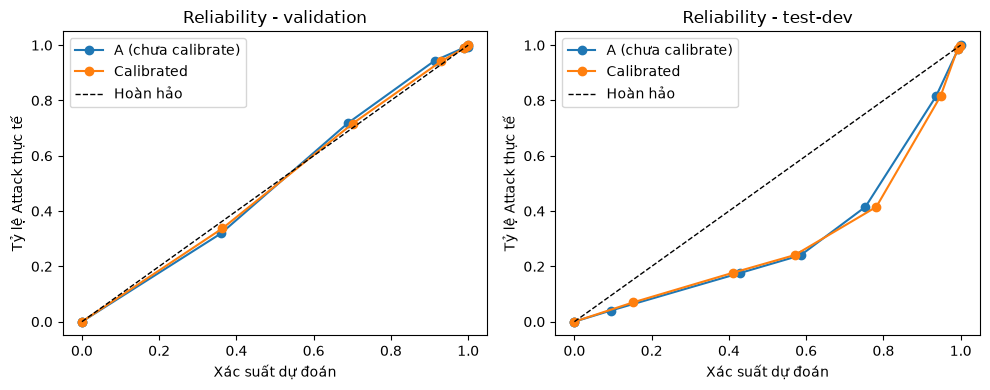

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, s in zip(axes, ys):
    for name, p in [('A (chưa calibrate)', proba_A[s]), ('Calibrated', proba_C[s])]:
        frac_pos, mean_pred = calibration_curve(ys[s], p, n_bins=10, strategy='quantile')
        ax.plot(mean_pred, frac_pos, marker='o', label=name)
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Hoàn hảo')
    ax.set_title(f'Reliability - {s}'); ax.set_xlabel('Xác suất dự đoán'); ax.set_ylabel('Tỷ lệ Attack thực tế')
    ax.legend()
plt.tight_layout(); plt.show()

## 4. Chọn ngưỡng theo ràng buộc `FPR <= 0.10` (Recall cao nhất)

Quy tắc được xác định **trước** khi xem test-final:
- **C_val**: ngưỡng chọn trên validation (phân bố train).
- **C_dev**: ngưỡng chọn trên test-dev (phân bố test).
- **Cấu hình cuối cùng = C_dev**, vì ràng buộc FPR áp dụng cho môi trường giống tập test. C_val cũng được đánh giá trên test-final như một phép so sánh định trước, để đo ảnh hưởng của việc chọn ngưỡng trên phân bố train.

In [14]:
def select_threshold(y_true, proba, fpr_max=FPR_MAX):
    cands = np.unique(np.r_[np.round(np.arange(0.05, 1.0, 0.01), 2), proba])
    rows = pd.DataFrame([metrics_at(y_true, proba, t) for t in cands])
    ok = rows[rows['fpr'] <= fpr_max]
    if ok.empty:
        return None, rows
    best = ok.sort_values(['recall', 'precision'], ascending=False).iloc[0]
    return float(best['threshold']), rows


thr_val, sweep_val = select_threshold(y_val, proba_C['validation'])
thr_dev, sweep_dev = select_threshold(y_dev, proba_C['test-dev'])
print(f'Ngưỡng C_val (validation): {thr_val}   |   Ngưỡng C_dev (test-dev): {thr_dev}')

grid = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
cols = ['threshold', 'precision', 'recall', 'f1', 'fpr']
for name, yt, p, thr in [('validation', y_val, proba_C['validation'], thr_val), ('test-dev', y_dev, proba_C['test-dev'], thr_dev)]:
    rows = [metrics_at(yt, p, t) for t in grid] + ([metrics_at(yt, p, thr)] if thr is not None else [])
    df = pd.DataFrame(rows)[cols].drop_duplicates('threshold').sort_values('threshold')
    df['FPR<=0.10'] = df['fpr'] <= FPR_MAX
    print(f'--- Bảng ngưỡng (model calibrated) trên {name} [ĐO]; ngưỡng được chọn = {thr}')
    display(df.round(4))

Ngưỡng C_val (validation): 0.463638696272519   |   Ngưỡng C_dev (test-dev): 0.7106307066499856
--- Bảng ngưỡng (model calibrated) trên validation [ĐO]; ngưỡng được chọn = 0.463638696272519


,threshold,precision,recall,f1,fpr,FPR<=0.10
0,0.3000,0.8628,0.9934,0.9235,0.1557,False
1,0.4000,0.8861,0.9776,0.9296,0.1238,False
7,0.4636,0.9049,0.9612,0.9322,0.0995,True
2,0.5000,0.9190,0.9496,0.9341,0.0825,True
3,0.6000,0.9461,0.9094,0.9274,0.0511,True
4,0.7000,0.9640,0.8729,0.9162,0.0321,True
5,0.8000,0.9756,0.8332,0.8988,0.0206,True
6,0.9000,0.9861,0.7445,0.8484,0.0103,True


--- Bảng ngưỡng (model calibrated) trên test-dev [ĐO]; ngưỡng được chọn = 0.7106307066499856


,threshold,precision,recall,f1,fpr,FPR<=0.10
0,0.3000,0.6062,0.9915,0.7524,0.3727,False
1,0.4000,0.6387,0.9730,0.7712,0.3185,False
2,0.5000,0.6954,0.9417,0.8000,0.2387,False
3,0.6000,0.7677,0.9005,0.8288,0.1576,False
4,0.7000,0.8266,0.8625,0.8442,0.1046,False
7,0.7106,0.8328,0.8594,0.8459,0.0998,True
5,0.8000,0.8790,0.8256,0.8515,0.0657,True
6,0.9000,0.9442,0.7485,0.8351,0.0256,True


## 5. So sánh A / B / C trên validation và test-dev

In [15]:
compare = {}
for s in ys:
    compare[f'A: RF @0.5 - {s}'] = metrics_at(ys[s], proba_A[s], 0.5)
    compare[f'B: Calibrated @0.5 - {s}'] = metrics_at(ys[s], proba_C[s], 0.5)
    if thr_val is not None:
        compare[f'C_val: Calibrated @{thr_val:.3f} - {s}'] = metrics_at(ys[s], proba_C[s], thr_val)
    if thr_dev is not None:
        compare[f'C_dev: Calibrated @{thr_dev:.3f} - {s}'] = metrics_at(ys[s], proba_C[s], thr_dev)
compare_table = table(compare)   # [ĐO]
print('Lưu ý: C_dev trên test-dev là kết quả trên chính tập dùng để chọn ngưỡng (lạc quan); số đo không thiên lệch nằm ở mục 6.')

,threshold,TP,TN,FP,FN,accuracy,precision,recall,f1,fpr,prevalence
A: RF @0.5 - validation,0.5000,9407.000000,9039.000000,926.000000,415.000000,0.9322,0.9104,0.9577,0.9335,0.0929,0.4964
B: Calibrated @0.5 - validation,0.5000,9327.000000,9143.000000,822.000000,495.000000,0.9334,0.9190,0.9496,0.9341,0.0825,0.4964
C_val: Calibrated @0.464 - validation,0.4636,9441.000000,8973.000000,992.000000,381.000000,0.9306,0.9049,0.9612,0.9322,0.0995,0.4964
C_dev: Calibrated @0.711 - validation,0.7106,8532.000000,9659.000000,306.000000,1290.000000,0.9193,0.9654,0.8687,0.9145,0.0307,0.4964
A: RF @0.5 - test-dev,0.5000,8806.000000,11810.000000,4207.000000,460.000000,0.8154,0.6767,0.9504,0.7905,0.2627,0.3665
B: Calibrated @0.5 - test-dev,0.5000,8726.000000,12194.000000,3823.000000,540.000000,0.8274,0.6954,0.9417,0.8000,0.2387,0.3665
C_val: Calibrated @0.464 - test-dev,0.4636,8855.000000,11615.000000,4402.000000,411.000000,0.8096,0.6679,0.9556,0.7863,0.2748,0.3665
C_dev: Calibrated @0.711 - test-dev,0.7106,7963.000000,14418.000000,1599.000000,1303.000000,0.8852,0.8328,0.8594,0.8459,0.0998,0.3665


Lưu ý: C_dev trên test-dev là kết quả trên chính tập dùng để chọn ngưỡng (lạc quan); số đo không thiên lệch nằm ở mục 6.


## 6. ĐÁNH GIÁ CUỐI CÙNG TRÊN TEST-FINAL (một lần, không thiên lệch)

Mọi lựa chọn (tham số, calibration, ngưỡng) đã cố định ở các mục trên. Không thay đổi gì sau khi chạy cell này.

In [16]:
X_fin, y_fin = features(test_final), test_final['label']
pA_fin, pC_fin = model_A.predict_proba(X_fin)[:, 1], model_cal.predict_proba(X_fin)[:, 1]
final_rows = {
    'Lần 1 (đã lưu) @0.5': metrics_at(y_fin, run1.predict_proba(X_fin)[:, 1], 0.5),
    'Lần 2 (đã lưu) @0.515': metrics_at(y_fin, run2.estimator_.predict_proba(X_fin)[:, 1], float(run2.best_threshold_)),
    'A: RF @0.5': metrics_at(y_fin, pA_fin, 0.5),
    'B: Calibrated @0.5': metrics_at(y_fin, pC_fin, 0.5),
}
if thr_val is not None:
    final_rows[f'C_val: Calibrated @{thr_val:.3f}'] = metrics_at(y_fin, pC_fin, thr_val)
if thr_dev is not None:
    final_rows[f'C_dev (CẤU HÌNH CHỌN): Calibrated @{thr_dev:.3f}'] = metrics_at(y_fin, pC_fin, thr_dev)
final_table = table(final_rows)   # [ĐO] test-final

,threshold,TP,TN,FP,FN,accuracy,precision,recall,f1,fpr,prevalence
Lần 1 (đã lưu) @0.5,0.5000,8795.000000,11827.000000,4190.000000,472.000000,0.8156,0.6773,0.9491,0.7905,0.2616,0.3665
Lần 2 (đã lưu) @0.515,0.5152,8746.000000,12206.000000,3811.000000,521.000000,0.8287,0.6965,0.9438,0.8015,0.2379,0.3665
A: RF @0.5,0.5000,8795.000000,11903.000000,4114.000000,472.000000,0.8186,0.6813,0.9491,0.7932,0.2569,0.3665
B: Calibrated @0.5,0.5000,8723.000000,12235.000000,3782.000000,544.000000,0.8289,0.6976,0.9413,0.8013,0.2361,0.3665
C_val: Calibrated @0.464,0.4636,8845.000000,11690.000000,4327.000000,422.000000,0.8122,0.6715,0.9545,0.7884,0.2702,0.3665
C_dev (CẤU HÌNH CHỌN): Calibrated @0.711,0.7106,7974.000000,14327.000000,1690.000000,1293.000000,0.8820,0.8251,0.8605,0.8424,0.1055,0.3665


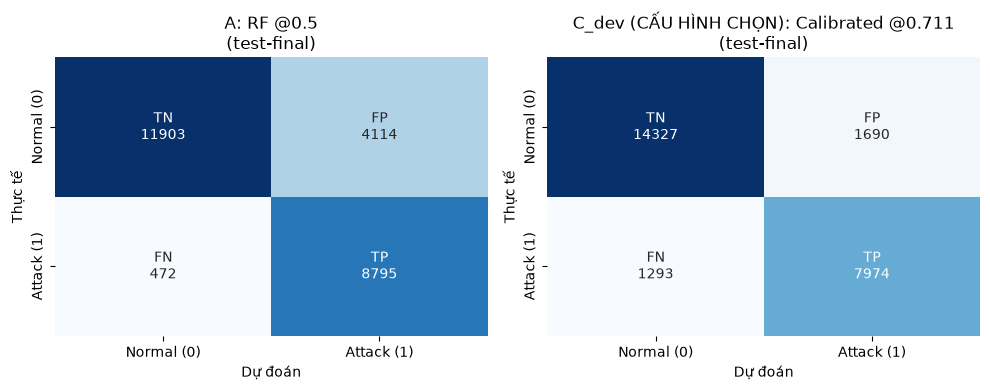

In [17]:
import seaborn as sns

show = ['A: RF @0.5'] + [k for k in final_rows if k.startswith('C_dev')]
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 4))
for ax, name in zip(np.atleast_1d(axes), show):
    r = final_rows[name]
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]])
    annot = [[f"TN\n{r['TN']}", f"FP\n{r['FP']}"], [f"FN\n{r['FN']}", f"TP\n{r['TP']}"]]
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'])
    ax.set_title(f'{name}\n(test-final)'); ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
plt.tight_layout(); plt.show()

In [18]:
def clean(d):
    return {k: (float(v) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, (np.integer,)) else v)
            for k, v in d.items()}


if not QUICK:
    joblib.dump({'model': model_cal, 'threshold': thr_dev}, os.path.join(models_dir, 'random_forest_v3_calibrated.joblib'),
                 compress=3)
out = {
    'fpr_constraint': FPR_MAX, 'threshold_C_val': thr_val, 'threshold_C_dev': thr_dev,
    'split_file': 'data/cleaned/test_split_v3.csv', 'best_params': best_params,
    'brier': brier.to_dict(), 'baseline': {k: clean(v) for k, v in base_rows.items()},
    'dev_compare': {k: clean(v) for k, v in compare.items()},
    'test_final': {k: clean(v) for k, v in final_rows.items()},
}
path = os.path.join(models_dir if not QUICK else os.environ['TEMP'], 'random_forest_v3_metrics.json')
json.dump(out, open(path, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('Đã lưu:', path)

Đã lưu: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\models\random_forest_v3_metrics.json
